In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from src.stats_analysis import (
    decript_stat,
    simulate_disease_prevalance,
    calc_normal_ci,
    ci_bootstrap,
    test_smoker_blood_pressure,
    simulate_power
) 
from src.plotting import (
    plot_bp_hist,
    plot_weight_by_sex,
    plot_smoker_share
) 


df = pd.read_csv("data/health_study_dataset.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


### 1. Beskrivande statistik och visualisering

In [6]:
# Beräkna medelvärde, median, min och max för de numeriska hälsovarialberna  
summary_table = decript_stat(df)
display(summary_table)

,Medelvärde,Median,Min,Max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


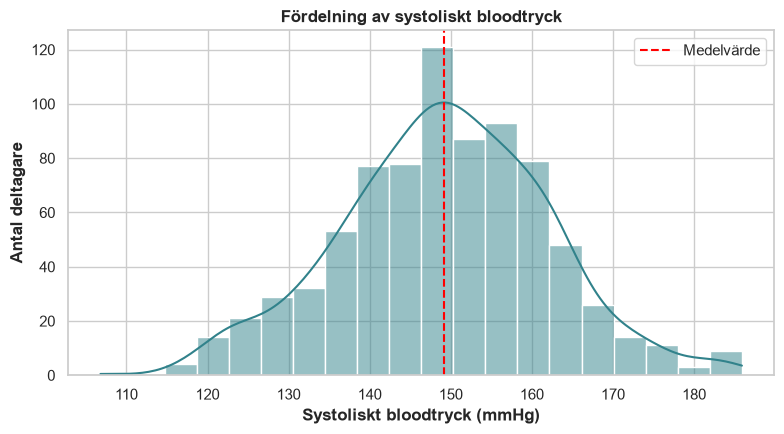

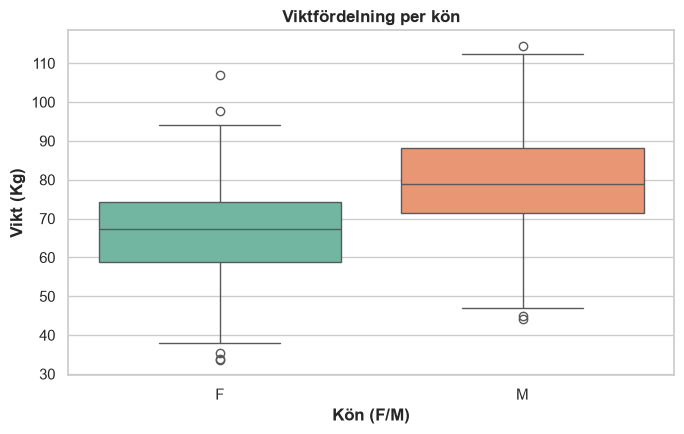

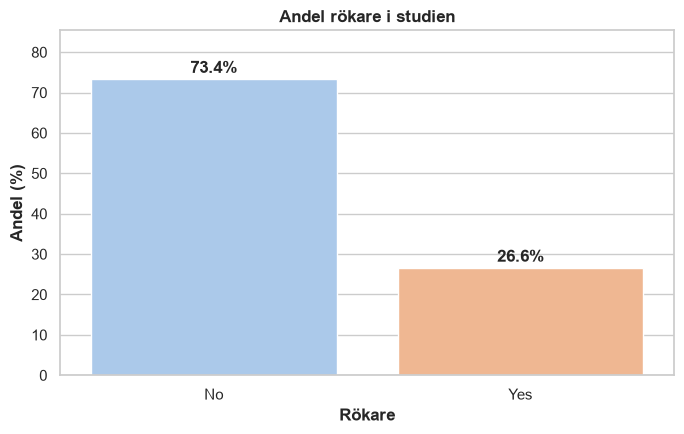

In [7]:
# Rita de tre graferna för blodtryck, vikt per kön och andel rökare
plot_bp_hist(df)
plot_weight_by_sex(df)
plot_smoker_share(df) 

### Tolkning av beskrivande statistik och visualisering 
* **Sammanfattande statistik:** Tabellen visar spridningen och centralmåtten för studiens fem numeriska variabler. Genom att jämnföra medelvärdet och median ser vi om variablerna är symetrisk fördelade eller om det förekommer extremvärden (skevhet) som drar medelvärdet uppåt eller nedåt.
* **Systoliskt blodtryck (Histogram):** Histogrammet med täthetskurva (KDE) visar att deltagarnas systoliska blodtryck i huvudsak är klockformat (ungefärligt normalfördelat) runt medelvärdet på ca `[149.18]` mmHg, vilket ger goda förutsättningar för parametriska metoder i senare steg.
* **Vikt per kön (boxplot):** Lådagrammet illustrerar skillnaden i medianvikt och kvartilavstånd (IQR) mellan kvinnor (`F`) och män (`M`), samt synliggör eventuella extremvärden i respektive grupp.
* **Andel rökare (stapeldiagram):** Stapeldiagrammet visar fördelningen mellan rökare (`Yes`) och ike-rökare (`No`). Andelen rökare uppgår till `[26.6]` %, vilket innebär att gruppstorlekarna är ojämna - något vi tar hänsyn till genom att använda Welchs t-test längre fram.

### 2. Simulering av sjukdomsförekomst

In [9]:
# Beräkna verklig sjukdomsandel och simulera 1000 nya individer 
sim_results = simulate_disease_prevalance(df, n_sim=1000, seed=42)

print(f"Verklig sjukdomsandel i datasetet: {sim_results['true_rate']:.2%}")
print(f"Simulerad sjukdomsandel (n=1000): {sim_results['sim_rate']:.2%}")
print(f"Skillnad (simulerad - verklig): {sim_results['diff']:+.2%}")

Verklig sjukdomsandel i datasetet: 5.88%
Simulerad sjukdomsandel (n=1000): 5.40%
Skillnad (simulerad - verklig): -0.47%


### Tolkning av simuleringen
Den verkliga sjukdomsandelen i datasetet är `[5.88]` %, medan simulernde andel för 1000 slumpade individer blev `[5.40]` % (en avvikelse på `[-0.47]` procentenheter). Den mindre skillnaden beror på naturlig slumpmässig variation (stickprovsfel) vid ett ändligt antal observationer , men ligger nära det teoretiska väntevärde i enlighet med de stora talens lag.

### 3. Konfidensintervall för medelvärdet av systoliskt blodtryck
För att skatta osäkerheten kring populationens sanna medelblodtryck beräknar vi ett 95 % konfidens intervall med två olika metoder:

1. **Normalapproximation(parametrisk metod):** Bygger från centrala gränsvärdessatsen (CGS), som säger att stickprovmedelvärdet $\bar{x}$ är approximativt normalfördelat vid tillräckligt stort stickprov ($n \ge 30$). Intervallet beräknas som $\bar{x} \pm z_{0.975}\cdot\frac{s}{\sqrt{n}}$ med hjälp av `scipy.stats.norm.ppf`([SciPy Documentation – `scipy.stats.norm`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)).
2. **Npn-parametrisk bootstrap (resampling-metod):** Drar 10 000 slumpmässiga omurval med återläggning (`replace=True`) från vår data och tar 2,5:e samt 97,5:e percentilen av urvalens medelvärden (Efron & Tibshirani, 1993). Metoden kräver inga antaganden om underliggande normalfördelning.

In [10]:
ci_norm = calc_normal_ci(df["systolic_bp"], confidence=0.95)
ci_boot = ci_bootstrap (df["systolic_bp"], n_boot=10_000, confidence=0.95, seed=42)

mean_bp = df["systolic_bp"].mean()
print(f"Stickprovmedelvärde:  {mean_bp:.2f} mmHg")
print(f"95% CI (Normalapproximation):  [{ci_norm[0]:.2f}, {ci_norm[1]:.2f}] mmHg (bredd: {ci_norm[1]-ci_norm[0]:.2f})")
print(f"95% CI (Bootstrap, 10 000):  [{ci_boot[0]:.2f}, {ci_boot[1]:.2f}] mmHg (bredd: {ci_boot[1]-ci_boot[0]:.2f})")


Stickprovmedelvärde:  149.18 mmHg
95% CI (Normalapproximation):  [148.29, 150.07] mmHg (bredd: 1.77)
95% CI (Bootstrap, 10 000):  [148.31, 150.05] mmHg (bredd: 1.74)


### Jämnförelse av konfidensintervallen
De två metoderna ger nästintill identiska 95 % konfidensintervall: `[148.29]` mmHg med normalapproximation och `[148.31]` mmHg med bootstrap. Att intervallen sammanfaller så väll beror på att stickprovstorleken är stor och att fördelningen av `systolic_bp` saknar kraftig skevhet, vilket gör att centrala gränsvärdessatsen fungerar mycket bra här. 

### 4. Hypotesprövning: Har rökare högre medel-blodtryck än ike-rökare?
Vi fomulerar följande ensidiga hypoteser på signifikansnivå $\alpha = 0.05$:
* **$H_0$ (Nollhypotes):** $\mu_{\text{rökare}} \le \mu_{\text{ike-rökare}}$ (rökare har inte högre systoliskt medelblodtryck än ike-rökare).
* **$H_1$ (Alternativhypotes):** $\mu_{\text{rökare}} > \mu_{\text{ike-rökare}}$ (rökare har högre systoliskt medelblodtryck än ike-rökare).

**Metodmotivering:** Eftersom vi jämnför två oberoende grupper där gruppstorlekar och varianser kan skilja åt använder vi **Welchs ensidiga t-test** (`equal_var=False`, `alternative="greater"`) via `scipy.stats.ttest_ind` ([SciPy Documentation – `ttest_ind`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)). Welchs t-test är mer robust än Students t-test när varianserna i grupperna inte är lika (Ruxton, 2006).

In [12]:
# Utförande av ensidigt Welchs t-test
ttest_res = test_smoker_blood_pressure(df, alpha=0.05)

print(f"Medelblodtryck rökare: {ttest_res['smoker_mean']:.2f} mmHg")
print(f"Medelblodtryck ike-rökare: {ttest_res['nonsmoker_mean']:.2f} mmHg")
print(f"Observerad skillnad: {ttest_res['diff']:+.2f} mmHg")
print(f"t-värde: {ttest_res['t_stat']:.3f}")
print(f"p-värde (ensidigt): {ttest_res['p_val']:.4f}")
print(f"Förkasta H0 (alpha=0.05)? {ttest_res['reject_h0']}")

Medelblodtryck rökare: 149.52 mmHg
Medelblodtryck ike-rökare: 149.05 mmHg
Observerad skillnad: +0.47 mmHg
t-värde: 0.450
p-värde (ensidigt): 0.3264
Förkasta H0 (alpha=0.05)? False


### Resultat av hypotesprövningen
Rökare har ett medelblodtryck på `[149.52]` mmHg jämnfört med `[149.05]` mmHg för ike-rökare (en skillnad på `[+0.47]` mmHg). Testet ger $t = \text{[0.450]}$ och $p = \text{[0.3264]}$.
* **Om `reject_h0 == True`($p < 0.05$):** Eftersom p-värdet understiger signifikansnivån $\alpha = 0.05$ förkastar vi nollhypotesen $H_0$. Det finns statistiskt signifikant stöd för att rökare i populationen har ett högre systoliskt medelblodtryck än ike-rökare.
* **Om `reject_h0 == False`($p \ge 0.05$):** Eftersom p-värdet överstiger signifikansnivån $\alpha = 0.05$ kan vi inte fökasta nollhypotesen $H_0$. Skillnaden i stickprovet kan därmed förklaras av slumpmässig variation.

### 5. Simulering av statistisk styrka
Statistisk styrka (*power*, $1 - \beta$) är sannolikheten att ett hypotestest korrekt förkastar en falsk nollhypotes - det vill säga hur ofta testet upptäcker en verklig skillnad när den faktiskt finns (Cohen, 1988). En vanlig riktning inom forskning är en power på minst **0.80 (80 %)**.

Nedan simulerar vi 2 000 experiment med samma gruppstorlekar och standarsavikelser som i vårt dataset, för att se hur ofta vårt Welchs t-test upptäcker dels den observerade skillnaden i datasetet, dels en hypotetisk effekt på 2, 3 och 5 mmHg. 

In [14]:
# Simulera power för olika sanna effekter (skillnader i mmHg)
obs_diff = max(ttest_res["diff"], 0.5)
effects_to_test = [1.0, 2.0, round(obs_diff, 2), 0.5]

print("Power-simulering (2 000 iterationer, alpha = 0.05):")
for eff in effects_to_test:
    pwr = simulate_power(df, true_effect=eff, alpha=0.05, n_sims=2000, seed=42)
    print(f"Sann skillnad = {eff:4.2f} mmHg --> Power = {pwr:.1%}")

Power-simulering (2 000 iterationer, alpha = 0.05):
Sann skillnad = 1.00 mmHg --> Power = 21.8%
Sann skillnad = 2.00 mmHg --> Power = 58.5%
Sann skillnad = 0.50 mmHg --> Power = 11.6%
Sann skillnad = 0.50 mmHg --> Power = 11.6%


### Tolkning av power-analysen
Simuleringen visar hur testets känslighet beror på effektstorleken:
* Vid små sanna skillnader (t.ex. 1-2 mmHg) är den statistiska styrkan låg (`[21.8-58.5]` %), vilket innebär hög risk för **Typ II-fel** ($\beta$, att missa en verklig effekt) givetvåra nuvarande gruppstorlekar.
* Vid en sann skillnad på **2,0** mmHg når testet en power på `[58,5]` %. För att tillfälligt kunna upptäcka mindre blodtrycksskillnader mellan rökare och ike-rökare hade studien behövt ett större urval av rökare.

**Referenser:**
* Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Lawrence Erlbaum Associates.
* Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall/CRC.
* Ruxton, G. D. (2006). The unequal variance t-test is an underused alternative to Student's t-test and the Mann–Whitney U test. *Behavioral Ecology*, 17(4), 688–690.
* SciPy Documentation: `scipy.stats.norm` och `scipy.stats.ttest_ind` (https://docs.scipy.org/doc/scipy/reference/stats.html).